# nb05 — ATAC QC, LSI, visualization and differential accessibility
**Question:** How does chromatin accessibility differ between observed E2 and Vehicle
cells, and how does ATAC structure relate to the existing RNA clusters?
Analyze MCF7 and T47D independently using exactly the RNA-QC-paired cells from nb02.

**Scope:** Scanpy handles available QC, neighbors, Leiden and UMAP. ATAC uses sparse
binary TF–IDF and truncated SVD/LSI, not RNA normalization/PCA.
Differential accessibility uses a depth-adjusted logistic score test implemented
with SciPy/statsmodels, not a Scanpy RNA DEG test.
No biological replicate mapping exists; every cell-level p/q value is exploratory.
Condition, submitted library and possible batch effects cannot be separated here.


## 1. Mount Drive and locate paired ATAC

In [1]:
try:
    from google.colab import drive
except ImportError:
    IN_COLAB=False
else:
    IN_COLAB=True
    drive.mount('/content/drive')
from pathlib import Path
import os
BASE=Path('/content/drive/MyDrive/breast-cancer-multiome-estrogen') if IN_COLAB else Path(os.environ.get('MULTIOME_PROJECT_ROOT',Path.cwd())).resolve()
if BASE.name=='notebooks': BASE=BASE.parent
for line in ('MCF7','T47D'):
    assert (BASE/f'data/processed/{line}_ATAC_paired_paper_qc.h5ad').exists(),'Run nb02 first.'
print(BASE)


/home/shoko/breast-cancer-multiome-estrogen


## 2. Dependencies and explicit choices

In [2]:
import importlib.util,importlib.metadata,sys,subprocess
packages={'scanpy':'scanpy==1.11.5','anndata':'anndata','numpy':'numpy','pandas':'pandas',
          'scipy':'scipy','sklearn':'scikit-learn','statsmodels':'statsmodels','igraph':'igraph','matplotlib':'matplotlib'}
missing=[v for k,v in packages.items() if importlib.util.find_spec(k) is None]
if missing:subprocess.check_call([sys.executable,'-m','pip','install',*missing])
VERSIONS={v.split('==')[0]:importlib.metadata.version(v.split('==')[0]) for v in packages.values()}
print(VERSIONS)


{'scanpy': '1.11.5', 'anndata': '0.12.19', 'numpy': '2.4.6', 'pandas': '2.3.3', 'scipy': '1.17.1', 'scikit-learn': '1.9.1', 'statsmodels': '0.15.0', 'igraph': '1.0.0', 'matplotlib': '3.11.2'}


## 3. Methods and limits
**QC:** report total supplied peak counts and detected peaks. These are not fragment
counts. No fragments means no valid TSS enrichment, FRiP or nucleosome-signal calculation.
Do not invent cutoffs or automatically remove further cells. Stop for zero-accessibility
cells rather than silently breaking RNA pairing.

**Embedding:** binarize accessibility; include peaks detected in at least 20 cells
and at most 95% of cells for LSI only. TF is binary accessibility divided by the
cell's total detected peaks across all supplied peaks; IDF=N/detected-cell count.
Use log1p(10,000 × TF × IDF), then 50-component randomized truncated SVD, seven
iterations, seed 42. This explicit Signac-style binary variant is a project choice,
not the scMKL paper's TF-IDF transformation. Plot depth correlation for every LSI
component. Predefine omission of component 1 and standardize components 2–31 for
neighbors (15), Leiden (resolution 0.5, igraph, two iterations), and UMAP (min_dist
0.3, 500 iterations). Omitting LSI1 does not guarantee removal of all depth effects.
RNA and ATAC cluster numbers are unrelated; inspect the overlap table.

**Differential accessibility:** independent of LSI peak selection, test a peak if
detected in >=10 cells and >=5% of either condition. Fit the null logistic model
treatment_E2 ~ standardized log1p(total supplied peak counts), and use an efficient
score test for adding each binary peak. This asks whether a peak is associated
with treatment after adjustment for depth; it is not a causal model.
The null model is shared across peaks. Variance accounts for fitted nuisance
parameters. Exclude degenerate peaks, apply BH across testable peaks within each line.
Report signed adjusted score, raw accessibility fractions/difference and unadjusted
log2 odds ratio (0.5 correction). Do not interpret that raw odds ratio as an adjusted
coefficient. Candidates require cell-level BH q<=0.05, absolute raw fraction
difference >=5 percentage points, and agreement of adjusted/raw directions.
No treatment permutation, independent-culture inference or motif analysis.

**Annotation:** GEO ATAC records state hg38. Peak coordinate origin remains unresolved.
Download the pinned UCSC curated RefSeq reference (checksum verified). Find nearest
TSS to peak midpoint under both 0-based half-open and 1-based closed interpretations.
Only label a provisional nearby-gene candidate when the nearest gene set agrees
and distance is <=100 kb under both. Keep ties and unmapped contigs explicit.
Nearest genes are not established regulatory targets. No BED export or
promoter-overlap claims are made until the coordinate convention is confirmed.

[Signac TF–IDF](https://stuartlab.org/signac/reference/runtfidf),
[statsmodels score test](https://www.statsmodels.org/stable/generated/statsmodels.genmod.generalized_linear_model.GLM.score_test.html),
[UCSC coordinates](https://genome.ucsc.edu/FAQ/FAQformat.html).


In [3]:
import json
CONFIG=json.loads('{"seed": 42, "embedding_min_cells": 20, "embedding_max_fraction": 0.95, "tfidf_scale": 10000, "lsi_components": 50, "lsi_iterations": 7, "neighbor_lsi_components": 30, "exclude_lsi1": true, "neighbors": 15, "leiden_resolution": 0.5, "leiden_iterations": 2, "umap_min_dist": 0.3, "umap_iterations": 500, "da_min_detected_cells": 10, "da_min_fraction_either": 0.05, "da_max_bh_q": 0.05, "da_min_abs_fraction_difference": 0.05, "da_depth_covariate": "standardized log1p(total peak counts)", "da_test": "logistic efficient score test: treatment ~ depth + binary peak; cell-level exploratory", "annotation_max_distance": 100000}')
REFERENCE=json.loads('{"assembly": "hg38", "assembly_source": "GEO GSM6418445 and GSM6418446 Assembly field", "peak_coordinate_origin": "unresolved; annotations require agreement under both 0-based half-open and 1-based closed interpretations", "annotation_url": "https://hgdownload.soe.ucsc.edu/goldenPath/hg38/database/ncbiRefSeqCurated.txt.gz", "annotation_file": "data/raw/reference/hg38_ncbiRefSeqCurated.txt.gz", "annotation_sha256": "67090326b606658bdabdfe5f8dcb97b7943ac802c7945399522be7174ec021ca", "reference_format": "UCSC genePredExt; txStart 0-based, txEnd exclusive", "download_date": "2026-10-10", "annotation_policy": "nearest TSS to peak midpoint, candidate genes only; report both coordinate interpretations and retain consensus"}')
print(json.dumps(CONFIG,indent=2))
print(json.dumps(REFERENCE,indent=2))

{
  "seed": 42,
  "embedding_min_cells": 20,
  "embedding_max_fraction": 0.95,
  "tfidf_scale": 10000,
  "lsi_components": 50,
  "lsi_iterations": 7,
  "neighbor_lsi_components": 30,
  "exclude_lsi1": true,
  "neighbors": 15,
  "leiden_resolution": 0.5,
  "leiden_iterations": 2,
  "umap_min_dist": 0.3,
  "umap_iterations": 500,
  "da_min_detected_cells": 10,
  "da_min_fraction_either": 0.05,
  "da_max_bh_q": 0.05,
  "da_min_abs_fraction_difference": 0.05,
  "da_depth_covariate": "standardized log1p(total peak counts)",
  "da_test": "logistic efficient score test: treatment ~ depth + binary peak; cell-level exploratory",
  "annotation_max_distance": 100000
}
{
  "assembly": "hg38",
  "assembly_source": "GEO GSM6418445 and GSM6418446 Assembly field",
  "peak_coordinate_origin": "unresolved; annotations require agreement under both 0-based half-open and 1-based closed interpretations",
  "annotation_url": "https://hgdownload.soe.ucsc.edu/goldenPath/hg38/database/ncbiRefSeqCurated.txt.gz",

## 4. Embedded implementation
Original nb02 objects remain unchanged; new outputs use nb05 paths.

In [4]:
"""ATAC-specific sparse LSI, Scanpy visualization and exploratory depth-adjusted DA."""
from pathlib import Path
import gc,gzip,hashlib,json,urllib.request
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from scipy import sparse
from scipy.stats import chi2,spearmanr
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import adjusted_rand_score
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

def digest(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for b in iter(lambda:f.read(1048576),b""):h.update(b)
    return h.hexdigest()

def save_table(df,path,index=False):
    df.to_csv(path,sep="\t",index=index,float_format="%.8g",lineterminator="\n")

def get_reference(root,ref):
    path=Path(root)/ref["annotation_file"]
    if not path.exists():
        path.parent.mkdir(parents=True,exist_ok=True)
        tmp=path.with_suffix(".partial")
        with urllib.request.urlopen(ref["annotation_url"],timeout=120) as response:
            tmp.write_bytes(response.read())
        if digest(tmp)!=ref["annotation_sha256"]:
            raise ValueError("Reference download changed; review provenance before using it.")
        tmp.replace(path)
    if digest(path)!=ref["annotation_sha256"]:raise ValueError("Reference checksum mismatch")
    rows=[]
    with gzip.open(path,"rt") as f:
        for line in f:
            v=line.rstrip().split("\t")
            rows.append((v[2],int(v[4]) if v[3]=="+" else int(v[5])-1,v[12]))
    return pd.DataFrame(rows,columns=["contig","tss0","gene"]).drop_duplicates()

def nearest_genes(var,tss,max_distance):
    lookup={}
    for chrom,g in tss.groupby("contig"):
        grouped=g.groupby("tss0").gene.agg(lambda v:";".join(sorted(set(v))))
        lookup[chrom]=(grouped.index.to_numpy(),grouped.to_numpy())
    def nearest(chrom,mid):
        if chrom not in lookup:return "",np.nan
        positions,names=lookup[chrom]
        i=np.searchsorted(positions,mid)
        candidates=[j for j in (i-1,i) if 0<=j<len(positions)]
        d=min(abs(positions[j]-mid) for j in candidates)
        genes=sorted({gene for j in candidates if abs(positions[j]-mid)==d for gene in names[j].split(";")})
        return ";".join(genes),d
    records=[]
    for peak,row in var.iterrows():
        # Midpoint of covered zero-based base positions under the two hypotheses.
        mid0=(row.start_as_supplied+row.end_as_supplied-1)/2
        mid1=(row.start_as_supplied+row.end_as_supplied-2)/2
        g0,d0=nearest(row.contig,mid0);g1,d1=nearest(row.contig,mid1)
        stable=bool(g0) and g0==g1
        near=stable and max(d0,d1)<=max_distance
        records.append((peak,g0,g1,d0,d1,stable,g0 if near else "",
                        "provisional_consensus" if near else "distant_or_ambiguous_or_unmapped"))
    return pd.DataFrame(records,columns=["peak","nearest_genes_if_0based","nearest_genes_if_1based",
        "distance_bp_if_0based","distance_bp_if_1based","coordinate_robust_nearest",
        "candidate_nearby_genes","annotation_status"]).set_index("peak")

def tfidf(binary,mask,scale):
    """Binary TF over all supplied peaks; IDF=N/detection count; log1p(scale*TF*IDF)."""
    totals=np.asarray(binary.sum(axis=1)).ravel()
    if np.any(totals<=0):raise ValueError("Zero-accessibility cells require explicit handling.")
    selected=binary[:,mask].astype(np.float64).tocsr()
    prevalence=np.asarray(selected.sum(axis=0)).ravel()
    idf=binary.shape[0]/prevalence
    selected=selected.multiply(1/totals[:,None]).multiply(idf[None,:]).tocsr()
    selected.data=np.log1p(scale*selected.data)
    assert np.isfinite(selected.data).all()
    return selected,idf

def depth_score_test(binary,y,depth):
    """Efficient score test of a binary peak added to treatment~log-depth."""
    z=np.log1p(np.asarray(depth,dtype=float))
    z=(z-z.mean())/max(z.std(),1e-12)
    design=np.column_stack([np.ones(len(y)),z]) if z.std()>0 else np.ones((len(y),1))
    fit=sm.GLM(y,design,family=sm.families.Binomial()).fit()
    if not fit.converged:raise ValueError("Depth-only logistic model did not converge.")
    mu=fit.predict();w=mu*(1-mu)
    information=design.T@(w[:,None]*design)
    if np.linalg.cond(information)>1e12:raise ValueError("Depth model is ill-conditioned.")
    nuisance=np.asarray(binary.T@(w[:,None]*design))
    variance=np.asarray(binary.T@w).ravel()-np.einsum(
        "ij,jk,ik->i",nuisance,np.linalg.inv(information),nuisance)
    score=np.asarray(binary.T@(y-mu)).ravel()
    valid=variance>1e-8
    signed=np.full(binary.shape[1],np.nan)
    signed[valid]=score[valid]/np.sqrt(variance[valid])
    p=np.full_like(signed,np.nan);p[valid]=chi2.sf(signed[valid]**2,1)
    return signed,p,valid,{"coefficients":fit.params.tolist(),"converged":bool(fit.converged),
                         "design":"treatment_E2 ~ intercept + standardized log1p(total peak counts)"}

def differential_accessibility(a,cfg):
    b=a.layers["binary"];y=a.obs.treatment.eq("E2").to_numpy().astype(float)
    n1=int(y.sum());n0=len(y)-n1
    if min(n1,n0)<2:raise ValueError("Both conditions are required.")
    c1=np.asarray(b[y==1].sum(axis=0)).ravel();c0=np.asarray(b[y==0].sum(axis=0)).ravel()
    p1=c1/n1;p0=c0/n0
    mask=((c1>=cfg["da_min_detected_cells"])&(p1>=cfg["da_min_fraction_either"]))|(
        (c0>=cfg["da_min_detected_cells"])&(p0>=cfg["da_min_fraction_either"]))
    universe=pd.DataFrame({"peak":a.var_names,"detected_E2":c1,"detected_Vehicle":c0,
        "fraction_E2":p1,"fraction_Vehicle":p0,"passes_prevalence":mask})
    score,p,valid,null=depth_score_test(b[:,mask],y,a.obs.atac_total_peak_counts.to_numpy())
    df=universe.loc[mask].copy()
    df["depth_adjusted_score"]=score;df["cell_level_p"]=p;df["testable"]=valid
    df["cell_level_BH_q"]=np.nan
    df.loc[valid,"cell_level_BH_q"]=multipletests(p[valid],method="fdr_bh")[1]
    df["fraction_difference_E2_minus_Vehicle"]=df.fraction_E2-df.fraction_Vehicle
    df["unadjusted_log2_odds_ratio"]=np.log2(((df.detected_E2+.5)/(n1-df.detected_E2+.5))/
        ((df.detected_Vehicle+.5)/(n0-df.detected_Vehicle+.5)))
    df["adjusted_direction"]=np.where(df.depth_adjusted_score>0,"E2","Vehicle")
    df["direction_agrees_with_raw_fraction"]=np.sign(df.depth_adjusted_score)==np.sign(df.fraction_difference_E2_minus_Vehicle)
    df["exploratory_candidate"]=(df.cell_level_BH_q<=cfg["da_max_bh_q"]) & (
        df.fraction_difference_E2_minus_Vehicle.abs()>=cfg["da_min_abs_fraction_difference"]) & df.direction_agrees_with_raw_fraction
    return df,universe,null

def figures_for_line(a,da,diagnostics,figures,line):
    fig,axs=plt.subplots(1,3,figsize=(13,4),layout="constrained")
    for condition,color in [("E2","#c44e52"),("Vehicle","#2878b5")]:
        obs=a.obs.loc[a.obs.treatment==condition]
        axs[0].hist(np.log10(obs.atac_total_peak_counts),bins=40,histtype="step",label=condition,color=color)
        axs[1].hist(obs.atac_n_peaks,bins=40,histtype="step",label=condition,color=color)
    axs[0].set(xlabel="log10 total peak counts",ylabel="Cells",title=f"{line}: available ATAC QC")
    axs[1].set(xlabel="Detected peaks",ylabel="Cells");axs[0].legend()
    axs[2].plot(diagnostics.component,diagnostics.depth_spearman,"o-",ms=3)
    axs[2].axhline(0,color="gray",lw=.6);axs[2].set(xlabel="LSI component",ylabel="Spearman r with log depth",title="Depth association")
    fig.savefig(figures/f"{line}_atac_qc_lsi.png",dpi=150);plt.close(fig)
    fig,axs=plt.subplots(2,3,figsize=(15,9),layout="constrained")
    for ax,col in zip(axs.flat,["treatment","atac_leiden","rna_leiden","log1p_atac_counts","rna_pct_counts_mt","LSI1"]):
        sc.pl.umap(a,color=col,ax=ax,show=False,size=7,frameon=False,title=f"{line}: {col}")
    fig.savefig(figures/f"{line}_atac_umap.png",dpi=150);plt.close(fig)
    fig,ax=plt.subplots(figsize=(8,6),layout="constrained")
    valid=da.testable
    color=np.where(da.exploratory_candidate,np.where(da.depth_adjusted_score>0,"#c44e52","#2878b5"),"#bbbbbb")
    ax.scatter(100*da.loc[valid,"fraction_difference_E2_minus_Vehicle"],
               -np.log10(da.loc[valid,"cell_level_BH_q"].clip(lower=1e-300)),
               c=color[valid],s=4,alpha=.6)
    ax.set(xlabel="Unadjusted accessibility difference: E2 − Vehicle (percentage points)",
           ylabel="-log10 depth-adjusted cell-level BH q (capped at 300)",
           title=f"{line}: exploratory differential accessibility")
    fig.savefig(figures/f"{line}_da_volcano.png",dpi=150);plt.close(fig)

def analyze_atac(root,line,cfg,ref):
    root=Path(root);tables=root/"results/tables/nb05";figures=root/"results/figures/nb05"
    tables.mkdir(parents=True,exist_ok=True);figures.mkdir(parents=True,exist_ok=True)
    path=root/f"data/processed/{line}_ATAC_paired_paper_qc.h5ad";before=digest(path)
    a=ad.read_h5ad(path);ids=a.obs_names.copy()
    assert sparse.issparse(a.X) and np.issubdtype(a.X.dtype,np.integer)
    assert np.all(a.layers["binary"].data==1)
    np.testing.assert_array_equal(a.X.indices,a.layers["binary"].indices)
    np.testing.assert_array_equal(a.X.indptr,a.layers["binary"].indptr)
    sc.pp.calculate_qc_metrics(a,percent_top=None,log1p=False,inplace=True)
    np.testing.assert_array_equal(a.obs.total_counts,a.obs.atac_total_peak_counts)
    a.obs["rna_leiden"]=a.obs.pop("leiden")
    original_rna_labels=a.obs.rna_leiden.copy()
    a.obs["log1p_atac_counts"]=np.log1p(a.obs.atac_total_peak_counts)
    detected=np.asarray(a.layers["binary"].sum(axis=0)).ravel()
    mask=(detected>=cfg["embedding_min_cells"])&(detected/a.n_obs<=cfg["embedding_max_fraction"])
    a.var["used_for_lsi"]=mask
    print(f"{line}: TF-IDF/LSI on {mask.sum()} peaks",flush=True)
    x,idf=tfidf(a.layers["binary"],mask,cfg["tfidf_scale"])
    svd=TruncatedSVD(n_components=cfg["lsi_components"],n_iter=cfg["lsi_iterations"],random_state=cfg["seed"])
    lsi=svd.fit_transform(x)
    a.obsm["X_lsi"]=lsi.astype(np.float32)
    diagnostics=pd.DataFrame({"component":np.arange(1,lsi.shape[1]+1),
        "depth_spearman":[spearmanr(lsi[:,i],a.obs.log1p_atac_counts).statistic for i in range(lsi.shape[1])],
        "explained_variance_ratio":svd.explained_variance_ratio_})
    save_table(diagnostics,tables/f"{line}_lsi_diagnostics.tsv")
    np.savez_compressed(root/f"data/processed/{line}_atac_lsi_model.npz",peak_ids=a.var_names[mask].to_numpy(dtype=str),
                        idf=idf,components=svd.components_,singular_values=svd.singular_values_)
    start=1 if cfg["exclude_lsi1"] else 0
    selected=lsi[:,start:start+cfg["neighbor_lsi_components"]]
    a.obsm["X_lsi_neighbors"]=((selected-selected.mean(axis=0))/selected.std(axis=0)).astype(np.float32)
    a.obs["LSI1"]=lsi[:,0]
    del x,lsi,svd;gc.collect()
    sc.pp.neighbors(a,use_rep="X_lsi_neighbors",n_neighbors=cfg["neighbors"],transformer="sklearn",random_state=cfg["seed"])
    sc.tl.leiden(a,resolution=cfg["leiden_resolution"],flavor="igraph",n_iterations=cfg["leiden_iterations"],
                 directed=False,random_state=cfg["seed"],key_added="atac_leiden")
    sc.tl.umap(a,min_dist=cfg["umap_min_dist"],maxiter=cfg["umap_iterations"],random_state=cfg["seed"])
    print(f"{line}: depth-adjusted differential accessibility",flush=True)
    da,universe,null=differential_accessibility(a,cfg)
    print(f"{line}: coordinate-sensitive nearest-TSS annotation",flush=True)
    annotations=nearest_genes(a.var,get_reference(root,ref),cfg["annotation_max_distance"])
    da=da.join(annotations,on="peak")
    save_table(da,root/f"data/processed/{line}_nb05_da_all.tsv")
    save_table(annotations,root/f"data/processed/{line}_nb05_peak_annotations.tsv",True)
    save_table(universe,tables/f"{line}_da_peak_universe.tsv")
    candidates=da.loc[da.exploratory_candidate].sort_values("cell_level_BH_q")
    save_table(candidates,root/f"data/processed/{line}_nb05_da_candidates.tsv")
    save_table(candidates.groupby("adjusted_direction").head(1000),tables/f"{line}_top_da_candidates.tsv")
    save_table(pd.crosstab(a.obs.atac_leiden,a.obs.treatment),tables/f"{line}_atac_cluster_treatment.tsv",True)
    save_table(pd.crosstab(a.obs.atac_leiden,a.obs.rna_leiden),tables/f"{line}_atac_rna_cluster_overlap.tsv",True)
    save_table(a.obs,tables/f"{line}_atac_cell_qc.tsv",True)
    coords=pd.DataFrame(a.obsm["X_umap"],index=a.obs_names,columns=["UMAP1","UMAP2"])
    save_table(coords.join(a.obs[["treatment","atac_leiden","rna_leiden"]]),tables/f"{line}_atac_embeddings.tsv",True)
    figures_for_line(a,da,diagnostics,figures,line)
    a.uns["nb05"]={"config_json":json.dumps(cfg),"reference_json":json.dumps(ref),
                  "X":"original integer peak counts; LSI from separate binary TF-IDF","source_sha256":before}
    output=root/f"data/processed/{line}_ATAC_nb05.h5ad"
    tmp=output.with_suffix(".partial.h5ad");a.write_h5ad(tmp,compression="gzip");tmp.replace(output)
    assert a.obs_names.equals(ids) and a.obs.rna_leiden.equals(original_rna_labels)
    assert np.isfinite(a.obsm["X_lsi"]).all() and np.isfinite(a.obsm["X_umap"]).all()
    assert digest(path)==before
    result={"cells":a.n_obs,"peaks":a.n_vars,"lsi_peaks":int(mask.sum()),"atac_clusters":int(a.obs.atac_leiden.nunique()),
        "da_prevalence_pass":len(da),"da_testable":int(da.testable.sum()),"da_candidates":len(candidates),
        "candidate_direction_counts":candidates.adjusted_direction.value_counts().to_dict(),
        "candidate_with_provisional_gene":int(candidates.candidate_nearby_genes.ne("").sum()),
        "RNA_ATAC_cluster_ARI":float(adjusted_rand_score(a.obs.rna_leiden,a.obs.atac_leiden)),
        "lsi1_depth_spearman":float(diagnostics.depth_spearman.iloc[0]),
        "null_depth_model":null,"source_sha256":before,"nb02_input_unchanged":True,
        "cells_and_rna_labels_preserved":True,"biological_replicates_identifiable":False,
        "coordinate_origin_confirmed":False,"annotation":"provisional nearest TSS, agreement under two coordinate conventions"}
    print(json.dumps(result,indent=2),flush=True)
    del a,da;gc.collect()
    return result


In [5]:
from IPython.display import Image,display
from datetime import datetime,timezone
sc.settings.verbosity=2
report={'run_at_utc':datetime.now(timezone.utc).isoformat(),'config':CONFIG,'reference':REFERENCE,
        'versions':VERSIONS,'cell_lines':{}}


## MCF7: QC → TF–IDF/LSI → Scanpy graph/UMAP → exploratory DA → provisional annotation

In [6]:
report['cell_lines']['MCF7']=analyze_atac(BASE,'MCF7',CONFIG,REFERENCE)

MCF7: TF-IDF/LSI on 152168 peaks


computing neighbors


    finished (0:00:11)


running Leiden clustering


    finished (0:00:00)


computing UMAP


    finished (0:00:10)


MCF7: depth-adjusted differential accessibility


MCF7: coordinate-sensitive nearest-TSS annotation


{
  "cells": 6019,
  "peaks": 206167,
  "lsi_peaks": 152168,
  "atac_clusters": 6,
  "da_prevalence_pass": 30678,
  "da_testable": 30678,
  "da_candidates": 1400,
  "candidate_direction_counts": {
    "Vehicle": 740,
    "E2": 660
  },
  "candidate_with_provisional_gene": 1318,
  "RNA_ATAC_cluster_ARI": 0.5092344432098544,
  "lsi1_depth_spearman": 0.9977899536437319,
  "null_depth_model": {
    "coefficients": [
      0.18649231002366726,
      -0.06356405188121836
    ],
    "converged": true,
    "design": "treatment_E2 ~ intercept + standardized log1p(total peak counts)"
  },
  "source_sha256": "45eb112c94f8f46edbc058bc7c2083f3341104616ab2f54b54f5550ff71268ac",
  "nb02_input_unchanged": true,
  "cells_and_rna_labels_preserved": true,
  "biological_replicates_identifiable": false,
  "coordinate_origin_confirmed": false,
  "annotation": "provisional nearest TSS, agreement under two coordinate conventions"
}


{
  "cells": 6019,
  "peaks": 206167,
  "lsi_peaks": 152168,
  "atac_clusters": 6,
  "da_prevalence_pass": 30678,
  "da_testable": 30678,
  "da_candidates": 1400,
  "candidate_direction_counts": {
    "Vehicle": 740,
    "E2": 660
  },
  "candidate_with_provisional_gene": 1318,
  "RNA_ATAC_cluster_ARI": 0.5092344432098544,
  "lsi1_depth_spearman": 0.9977899536437319,
  "null_depth_model": {
    "coefficients": [
      0.18649231002366726,
      -0.06356405188121836
    ],
    "converged": true,
    "design": "treatment_E2 ~ intercept + standardized log1p(total peak counts)"
  },
  "source_sha256": "45eb112c94f8f46edbc058bc7c2083f3341104616ab2f54b54f5550ff71268ac",
  "nb02_input_unchanged": true,
  "cells_and_rna_labels_preserved": true,
  "biological_replicates_identifiable": false,
  "coordinate_origin_confirmed": false,
  "annotation": "provisional nearest TSS, agreement under two coordinate conventions"
}


,peak,detected_E2,detected_Vehicle,fraction_E2,fraction_Vehicle,passes_prevalence,depth_adjusted_score,cell_level_p,testable,cell_level_BH_q,...,adjusted_direction,direction_agrees_with_raw_fraction,exploratory_candidate,nearest_genes_if_0based,nearest_genes_if_1based,distance_bp_if_0based,distance_bp_if_1based,coordinate_robust_nearest,candidate_nearby_genes,annotation_status
0,chr10-96832034-96832805,1249,0,0.379751,0.000000,True,37.566247,7.650119e-309,True,2.346904e-304,...,E2,True,True,LOC102723665,LOC102723665,38.0,38.5,True,LOC102723665,provisional_consensus
1,chr10-102643391-102644218,0,746,0.000000,0.273260,True,-32.132887,1.531702e-226,True,2.349477e-222,...,Vehicle,True,True,TRIM8-DT,TRIM8-DT,616.0,615.5,True,TRIM8-DT,provisional_consensus
2,chr12-1594269-1595025,0,737,0.000000,0.269963,True,-31.898945,2.761548e-223,True,2.823959e-219,...,Vehicle,True,True,FBXL14,FBXL14,66.5,66.0,True,FBXL14,provisional_consensus
3,chr14-64504793-64505533,0,726,0.000000,0.265934,True,-31.667817,4.311682e-220,True,3.306844e-216,...,Vehicle,True,True,ZBTB25,ZBTB25,49.5,50.0,True,ZBTB25,provisional_consensus
4,chr7-28958298-28958891,0,724,0.000000,0.265201,True,-31.534046,2.967359e-218,True,1.820653e-214,...,Vehicle,True,True,TRIL,TRIL,265.0,264.5,True,TRIL,provisional_consensus
5,chr17-68512048-68512551,0,712,0.000000,0.260806,True,-31.277495,9.442765e-215,True,4.828086e-211,...,Vehicle,True,True,PRKAR1A,PRKAR1A,79.0,79.5,True,PRKAR1A,provisional_consensus
6,chr9-127785200-127785917,0,698,0.000000,0.255678,True,-30.958122,1.975359e-210,True,8.657150e-207,...,Vehicle,True,True,MIR3960,MIR3960,274.0,274.5,True,MIR3960,provisional_consensus
7,chr11-65420845-65421697,0,622,0.000000,0.227839,True,-28.927149,5.440787e-184,True,2.086406e-180,...,Vehicle,True,True,NEAT1,NEAT1,1526.5,1527.0,True,NEAT1,provisional_consensus
8,chr3-170358054-170358712,799,0,0.242931,0.000000,True,28.636277,2.376109e-180,True,8.099364e-177,...,E2,True,True,SKIL,SKIL,668.5,668.0,True,SKIL,provisional_consensus
9,chr6-12287748-12288685,808,0,0.245667,0.000000,True,28.586155,9.986570e-180,True,3.063680e-176,...,E2,True,True,EDN1,EDN1,198.0,197.5,True,EDN1,provisional_consensus


,atac_leiden,E2,Vehicle
0,0,2133,144
1,1,560,2
2,2,381,73
3,3,17,2326
4,4,138,151
5,5,60,34


,atac_leiden,0,1,2,3,4,5,6,7,8
0,0,1143,56,86,733,180,20,36,11,12
1,1,48,16,339,145,0,6,2,6,0
2,2,3,0,7,368,0,71,4,1,0
3,3,5,43,10,10,1988,251,26,6,4
4,4,6,61,9,4,8,5,186,0,10
5,5,1,1,1,2,3,1,1,83,1


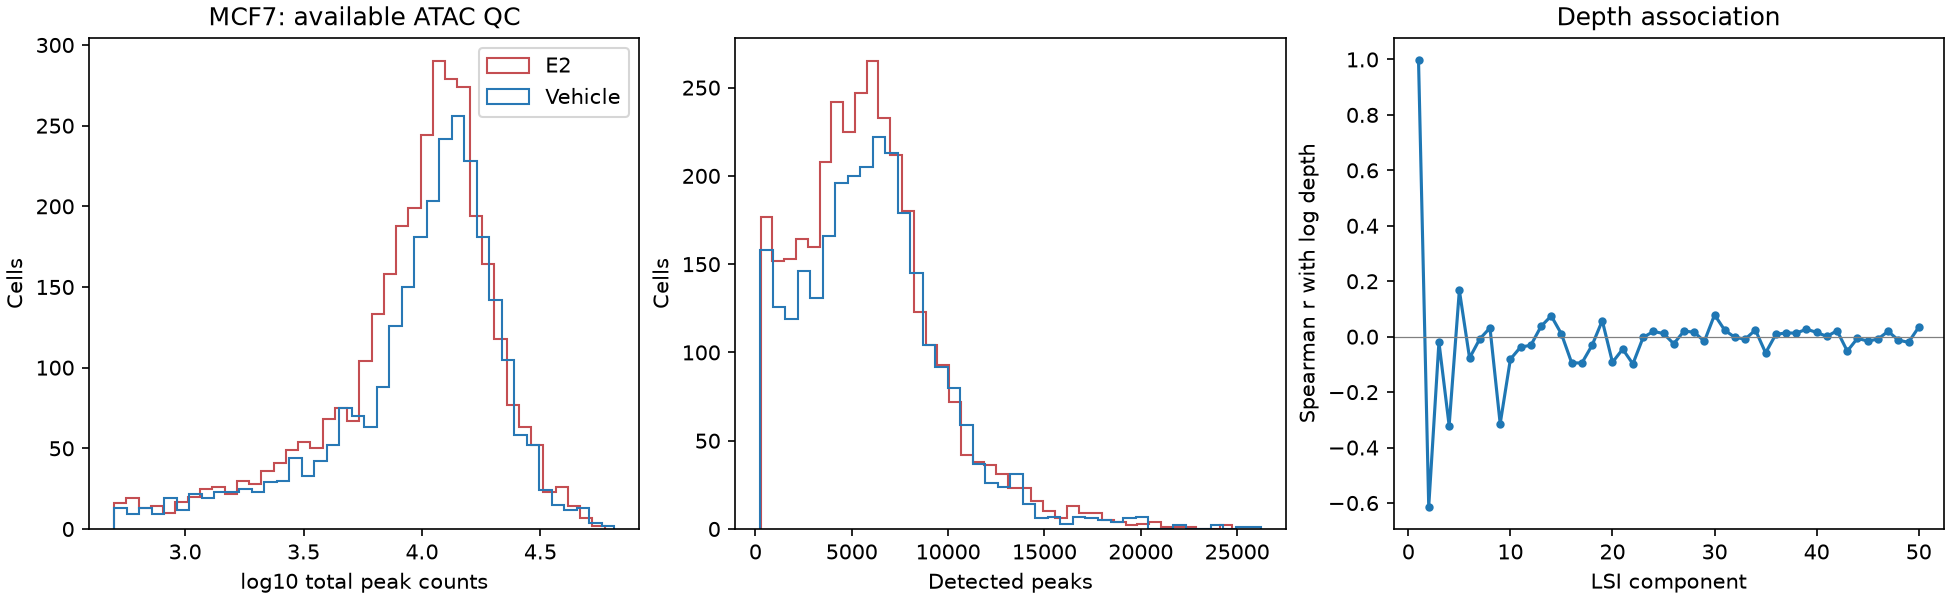

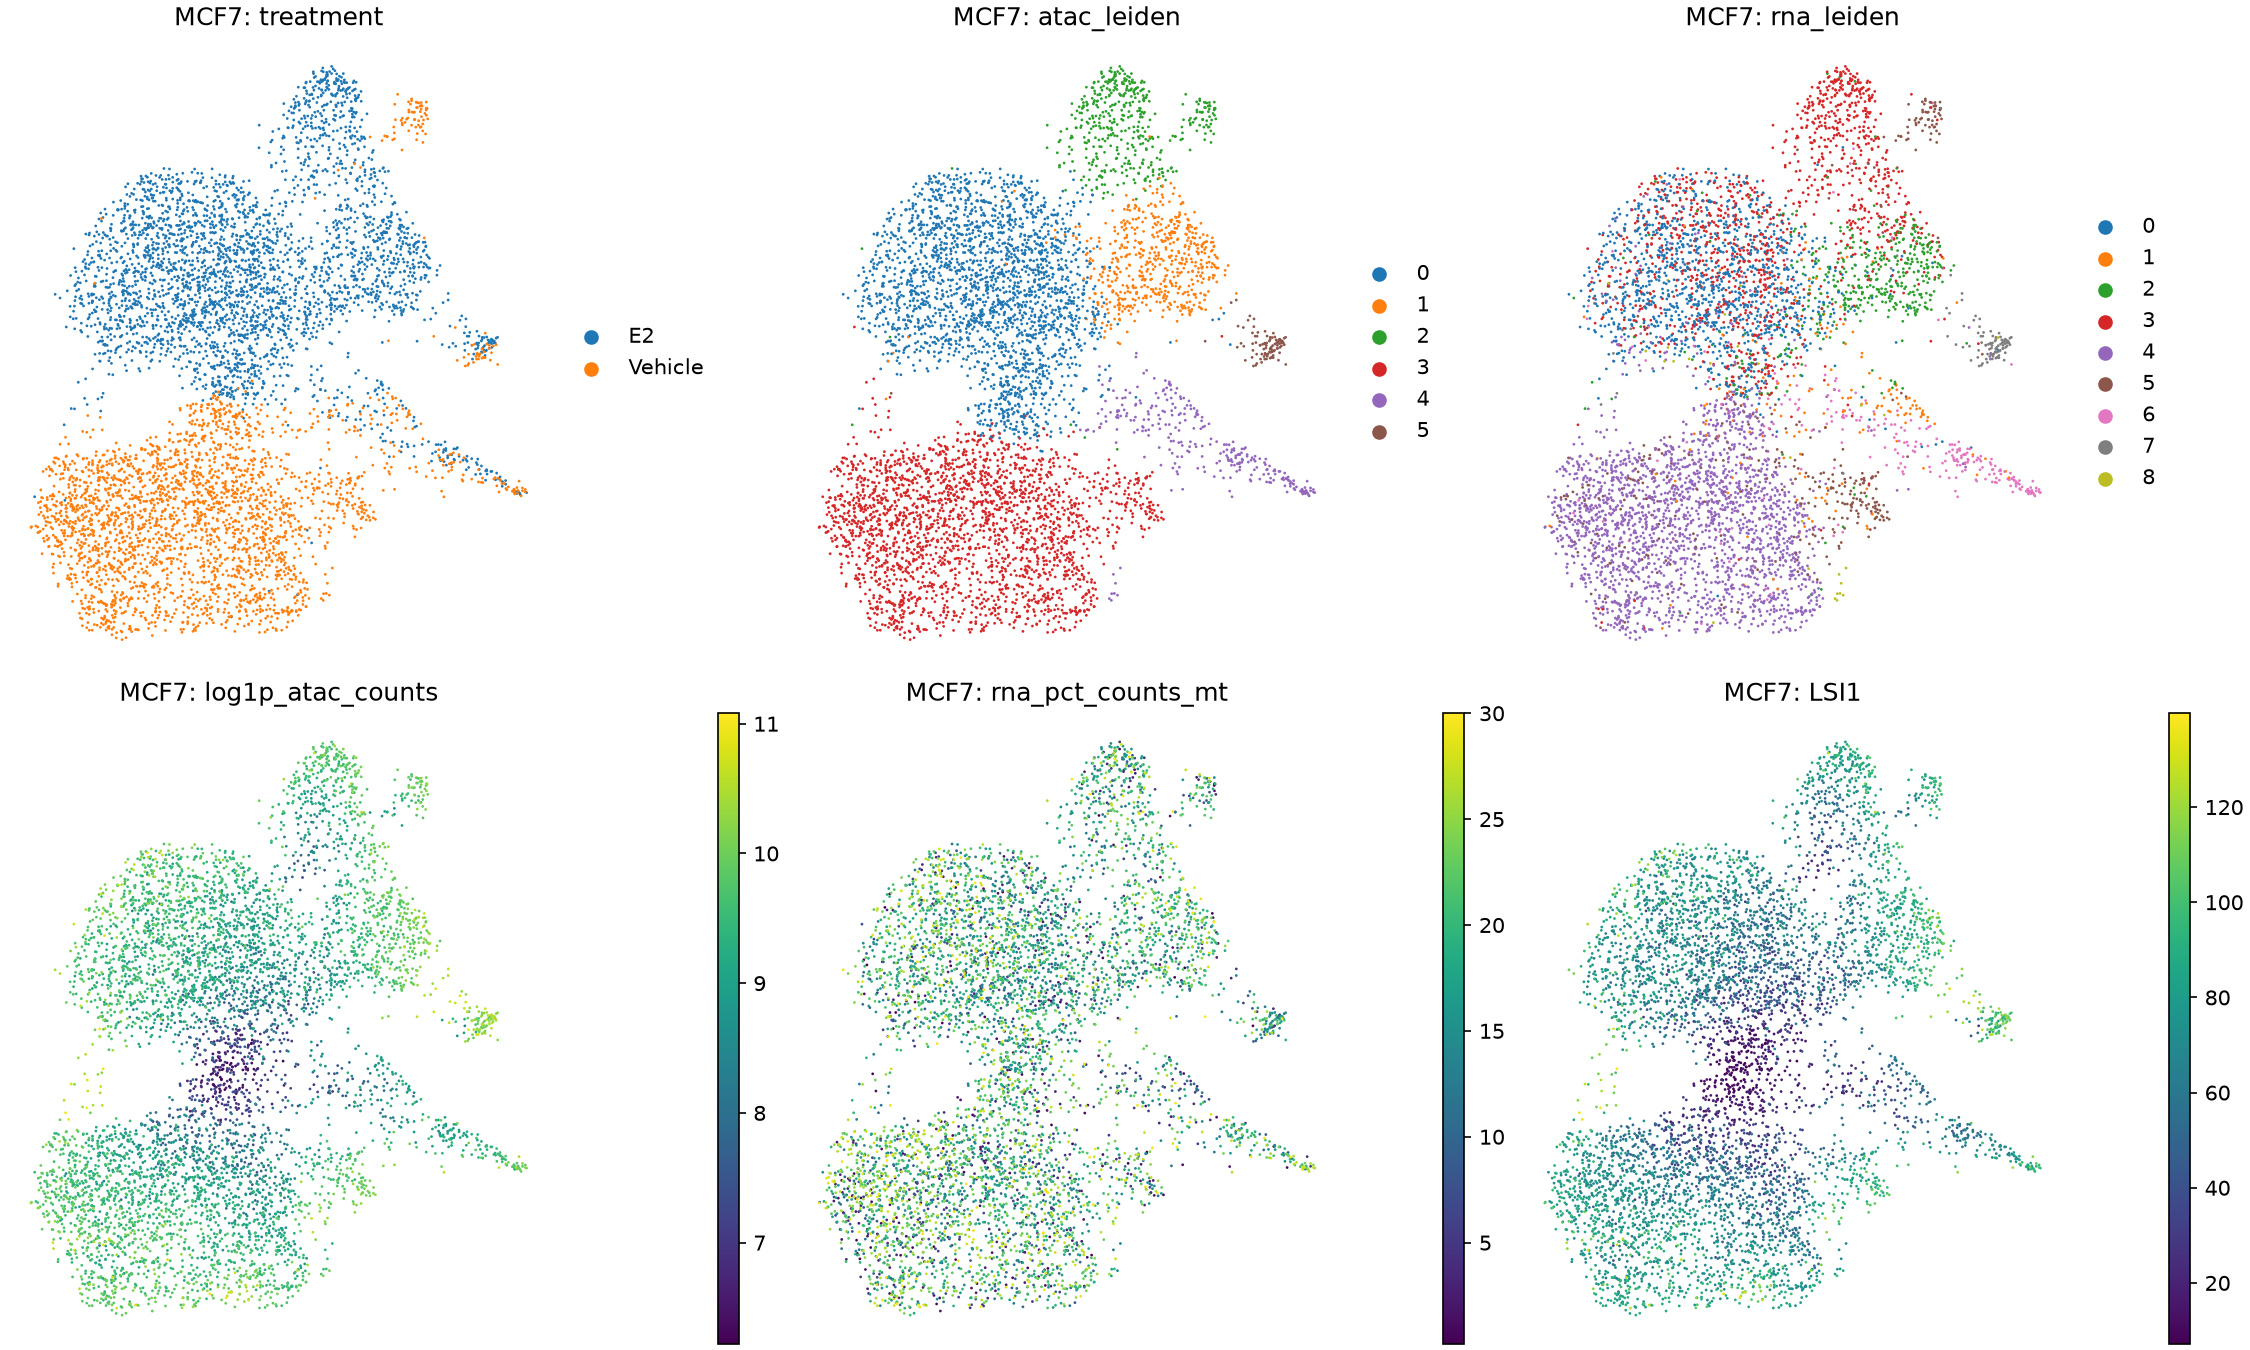

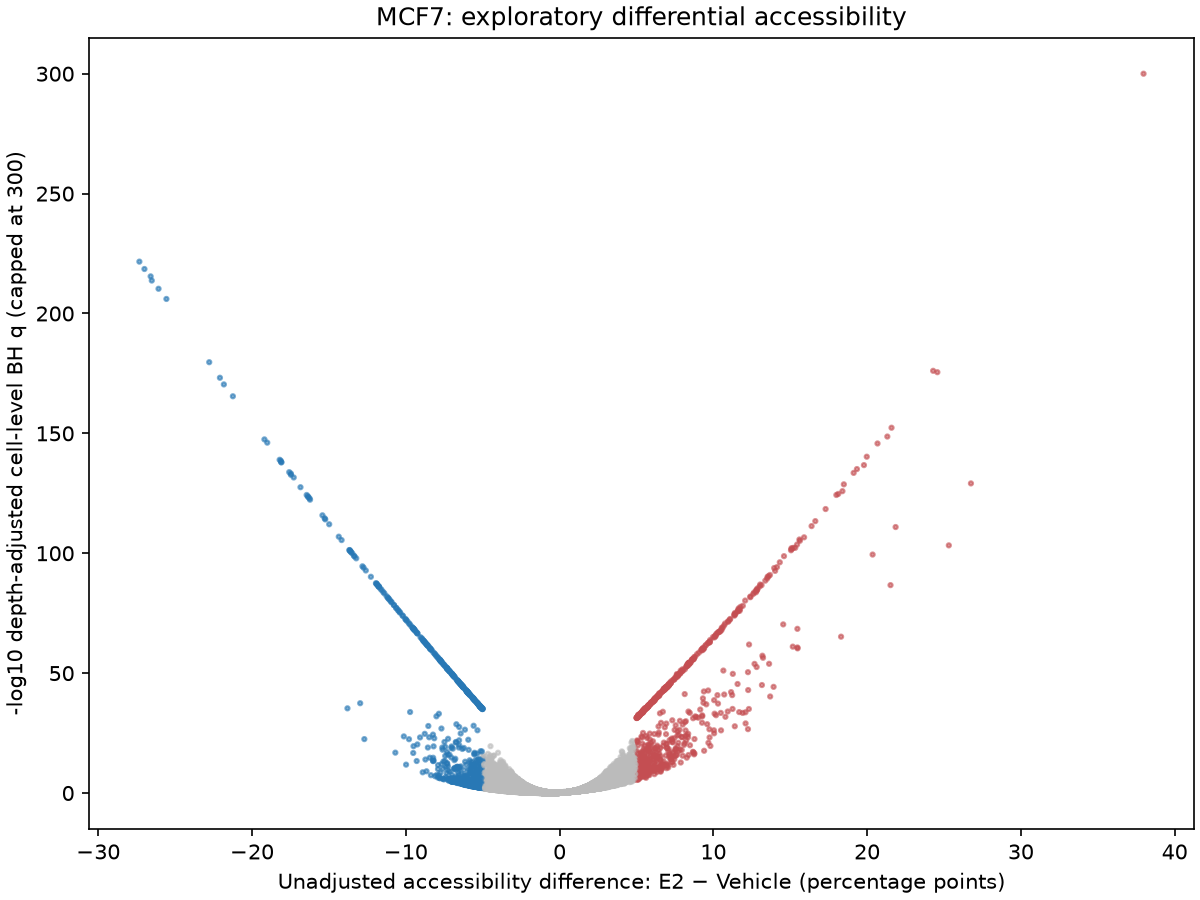

In [7]:
print(json.dumps(report['cell_lines']['MCF7'],indent=2))
tables=BASE/'results/tables/nb05'
display(pd.read_csv(tables/'MCF7_top_da_candidates.tsv',sep='\t').head(20))
display(pd.read_csv(tables/'MCF7_atac_cluster_treatment.tsv',sep='\t'))
display(pd.read_csv(tables/'MCF7_atac_rna_cluster_overlap.tsv',sep='\t'))
for suffix in ('atac_qc_lsi','atac_umap','da_volcano'):
    display(Image(filename=str(BASE/'results/figures/nb05'/f'MCF7_{suffix}.png')))


## T47D: QC → TF–IDF/LSI → Scanpy graph/UMAP → exploratory DA → provisional annotation

In [8]:
report['cell_lines']['T47D']=analyze_atac(BASE,'T47D',CONFIG,REFERENCE)

T47D: TF-IDF/LSI on 169654 peaks


computing neighbors


    finished (0:00:00)


running Leiden clustering


    finished (0:00:00)


computing UMAP


    finished (0:00:08)


T47D: depth-adjusted differential accessibility


T47D: coordinate-sensitive nearest-TSS annotation


{
  "cells": 6562,
  "peaks": 206167,
  "lsi_peaks": 169654,
  "atac_clusters": 9,
  "da_prevalence_pass": 44380,
  "da_testable": 44380,
  "da_candidates": 2367,
  "candidate_direction_counts": {
    "Vehicle": 1556,
    "E2": 811
  },
  "candidate_with_provisional_gene": 2241,
  "RNA_ATAC_cluster_ARI": 0.2735734528251344,
  "lsi1_depth_spearman": 0.9990847729158713,
  "null_depth_model": {
    "coefficients": [
      0.174088749716647,
      -0.10029791533373986
    ],
    "converged": true,
    "design": "treatment_E2 ~ intercept + standardized log1p(total peak counts)"
  },
  "source_sha256": "7ba972d4ce358af8d75f68acefda55fab96a9fad297f7b6f88afa5e626a0cf2a",
  "nb02_input_unchanged": true,
  "cells_and_rna_labels_preserved": true,
  "biological_replicates_identifiable": false,
  "coordinate_origin_confirmed": false,
  "annotation": "provisional nearest TSS, agreement under two coordinate conventions"
}


{
  "cells": 6562,
  "peaks": 206167,
  "lsi_peaks": 169654,
  "atac_clusters": 9,
  "da_prevalence_pass": 44380,
  "da_testable": 44380,
  "da_candidates": 2367,
  "candidate_direction_counts": {
    "Vehicle": 1556,
    "E2": 811
  },
  "candidate_with_provisional_gene": 2241,
  "RNA_ATAC_cluster_ARI": 0.2735734528251344,
  "lsi1_depth_spearman": 0.9990847729158713,
  "null_depth_model": {
    "coefficients": [
      0.174088749716647,
      -0.10029791533373986
    ],
    "converged": true,
    "design": "treatment_E2 ~ intercept + standardized log1p(total peak counts)"
  },
  "source_sha256": "7ba972d4ce358af8d75f68acefda55fab96a9fad297f7b6f88afa5e626a0cf2a",
  "nb02_input_unchanged": true,
  "cells_and_rna_labels_preserved": true,
  "biological_replicates_identifiable": false,
  "coordinate_origin_confirmed": false,
  "annotation": "provisional nearest TSS, agreement under two coordinate conventions"
}


,peak,detected_E2,detected_Vehicle,fraction_E2,fraction_Vehicle,passes_prevalence,depth_adjusted_score,cell_level_p,testable,cell_level_BH_q,...,adjusted_direction,direction_agrees_with_raw_fraction,exploratory_candidate,nearest_genes_if_0based,nearest_genes_if_1based,distance_bp_if_0based,distance_bp_if_1based,coordinate_robust_nearest,candidate_nearby_genes,annotation_status
0,chr17-59839003-59839742,1721,0,0.482749,0.000000,True,46.481579,0.000000e+00,True,0.000000e+00,...,E2,True,True,MIR21,MIR21,1893.0,1893.5,True,MIR21,provisional_consensus
1,chr20-50733144-50733956,1413,0,0.396353,0.000000,True,40.803419,0.000000e+00,True,0.000000e+00,...,E2,True,True,PARD6B,PARD6B,1970.5,1970.0,True,PARD6B,provisional_consensus
2,chr17-68512048-68512551,0,1358,0.000000,0.453120,True,-45.564625,0.000000e+00,True,0.000000e+00,...,Vehicle,True,True,PRKAR1A,PRKAR1A,79.0,79.5,True,PRKAR1A,provisional_consensus
3,chr17-68291866-68292267,0,1176,0.000000,0.392392,True,-41.442860,0.000000e+00,True,0.000000e+00,...,Vehicle,True,True,ARSG,ARSG,68.0,68.5,True,ARSG,provisional_consensus
4,chr20-50793282-50793852,1231,0,0.345302,0.000000,True,37.411636,2.527637e-306,True,2.243531e-302,...,E2,True,True,BCAS4,BCAS4,1326.5,1327.0,True,BCAS4,provisional_consensus
5,chr2-44167755-44168197,0,988,0.000000,0.329663,True,-37.176859,1.614577e-302,True,1.194249e-298,...,Vehicle,True,True,PPM1B,PPM1B,898.5,899.0,True,PPM1B,provisional_consensus
6,chr10-96832034-96832805,1195,0,0.335203,0.000000,True,36.542005,2.388765e-292,True,1.514477e-288,...,E2,True,True,LOC102723665,LOC102723665,38.0,38.5,True,LOC102723665,provisional_consensus
7,chr9-89604581-89605395,0,950,0.000000,0.316984,True,-36.415512,2.419076e-290,True,1.341983e-286,...,Vehicle,True,True,GADD45G,GADD45G,23.5,24.0,True,GADD45G,provisional_consensus
8,chr1-149885263-149885981,0,945,0.000000,0.315315,True,-36.229510,2.089233e-287,True,1.030224e-283,...,Vehicle,True,True,H2BC21,H2BC21,1059.5,1060.0,True,H2BC21,provisional_consensus
9,chr20-53785044-53785591,1141,0,0.320056,0.000000,True,35.823355,4.782072e-281,True,2.122283e-277,...,E2,True,True,SUMO1P1,SUMO1P1,90391.0,90391.5,True,SUMO1P1,provisional_consensus


,atac_leiden,E2,Vehicle
0,0,656,5
1,1,1172,6
2,2,627,689
3,3,460,161
4,4,9,1021
5,5,174,197
6,6,285,276
7,7,159,59
8,8,23,583


,atac_leiden,0,1,2,3,4,5,6,7
0,0,450,61,35,13,0,30,66,6
1,1,28,859,35,23,52,31,141,9
2,2,37,420,217,33,400,78,116,15
3,3,24,414,73,16,88,3,0,3
4,4,1,16,139,19,787,9,53,6
5,5,14,129,161,7,15,4,33,8
6,6,4,20,11,194,31,278,12,11
7,7,0,1,3,1,1,2,2,208
8,8,12,4,521,14,24,17,9,5


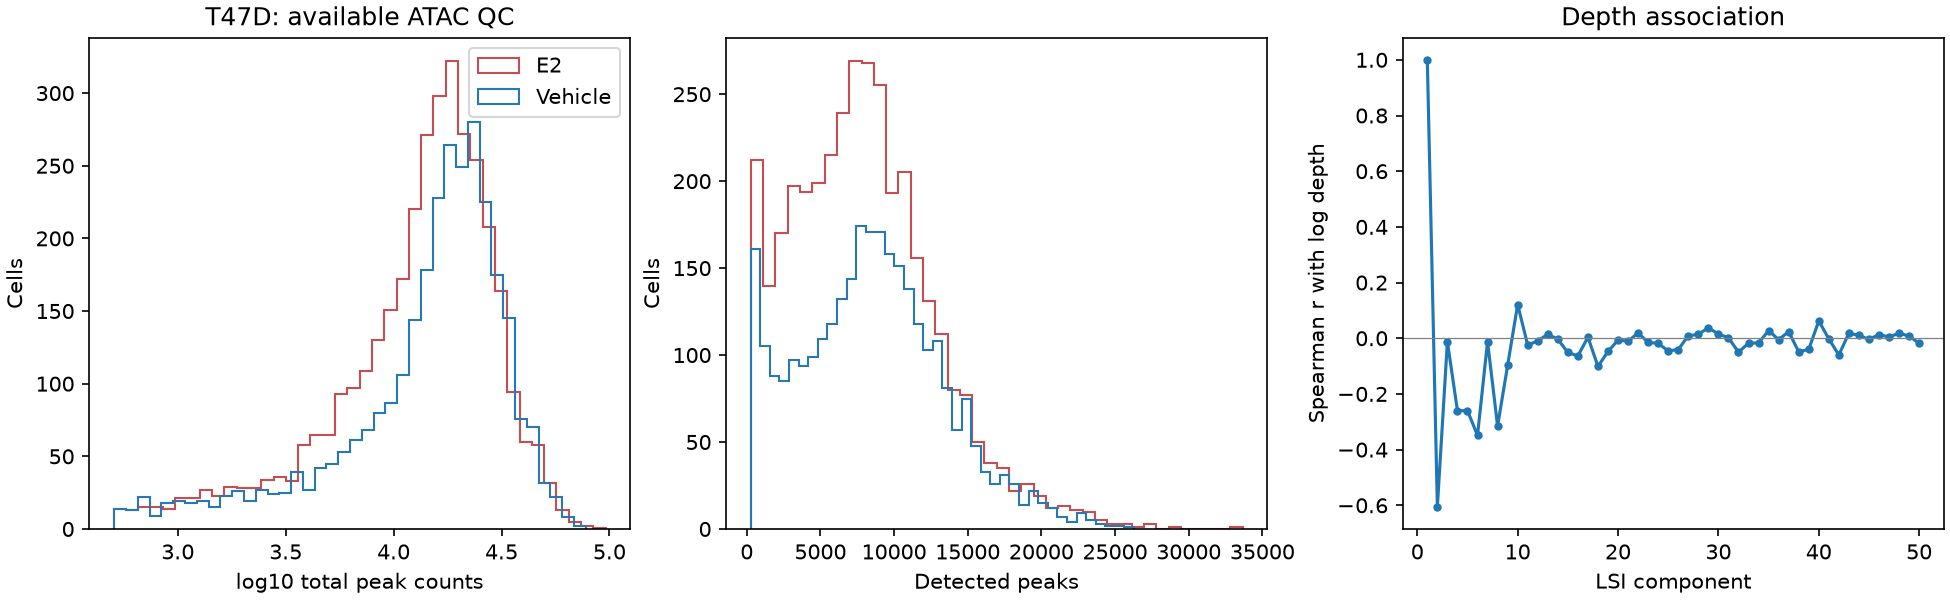

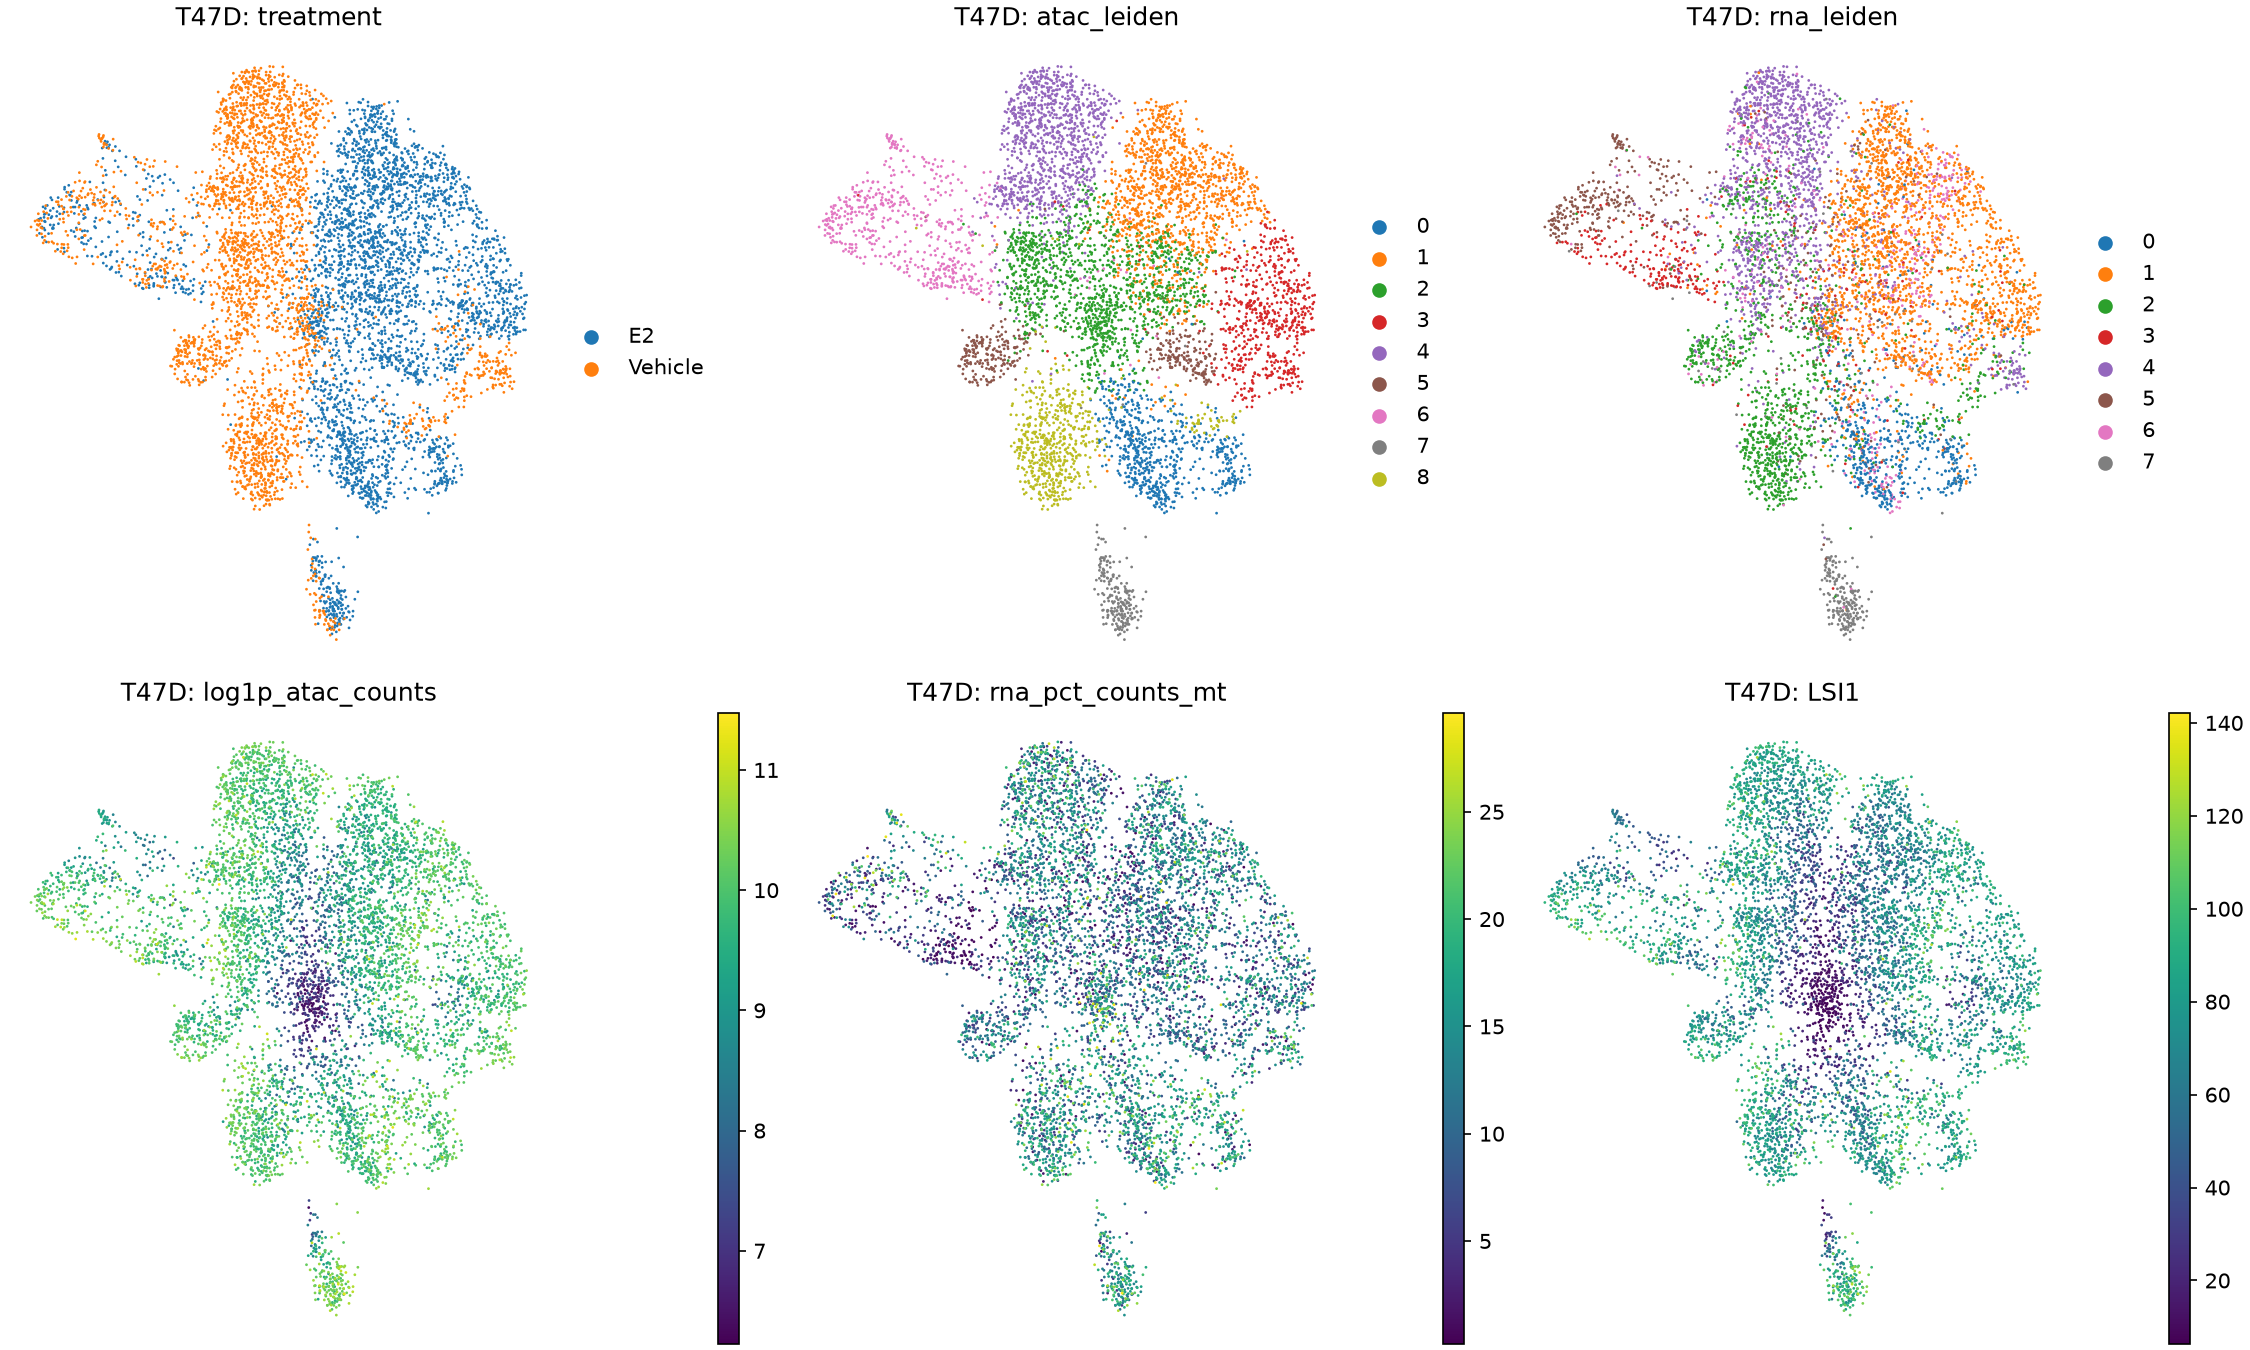

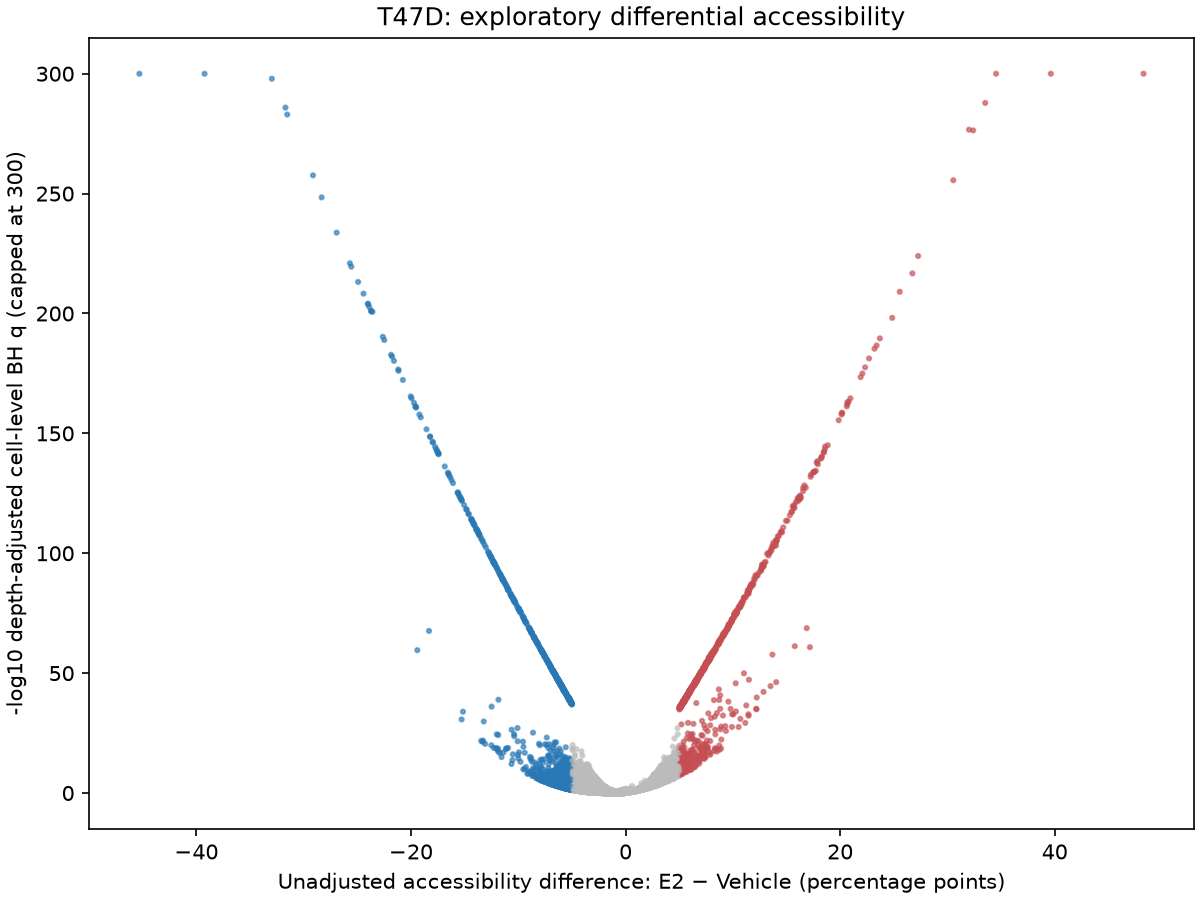

In [9]:
print(json.dumps(report['cell_lines']['T47D'],indent=2))
tables=BASE/'results/tables/nb05'
display(pd.read_csv(tables/'T47D_top_da_candidates.tsv',sep='\t').head(20))
display(pd.read_csv(tables/'T47D_atac_cluster_treatment.tsv',sep='\t'))
display(pd.read_csv(tables/'T47D_atac_rna_cluster_overlap.tsv',sep='\t'))
for suffix in ('atac_qc_lsi','atac_umap','da_volcano'):
    display(Image(filename=str(BASE/'results/figures/nb05'/f'T47D_{suffix}.png')))


## Save report and interpret cautiously

In [10]:
(BASE/'results/tables/nb05/atac_summary.json').write_text(json.dumps(report,indent=2)+'\n')
display(pd.DataFrame(report['cell_lines']).T)


,cells,peaks,lsi_peaks,atac_clusters,da_prevalence_pass,da_testable,da_candidates,candidate_direction_counts,candidate_with_provisional_gene,RNA_ATAC_cluster_ARI,lsi1_depth_spearman,null_depth_model,source_sha256,nb02_input_unchanged,cells_and_rna_labels_preserved,biological_replicates_identifiable,coordinate_origin_confirmed,annotation
MCF7,6019,206167,152168,6,30678,30678,1400,"{'Vehicle': 740, 'E2': 660}",1318,0.509234,0.99779,"{'coefficients': [0.18649231002366726, -0.0635...",45eb112c94f8f46edbc058bc7c2083f3341104616ab2f5...,True,True,False,False,"provisional nearest TSS, agreement under two c..."
T47D,6562,206167,169654,9,44380,44380,2367,"{'Vehicle': 1556, 'E2': 811}",2241,0.273573,0.999085,"{'coefficients': [0.174088749716647, -0.100297...",7ba972d4ce358af8d75f68acefda55fab96a9fad297f7b...,True,True,False,False,"provisional nearest TSS, agreement under two c..."


All supplied peaks and paired cells remain in the new AnnData object; only
the LSI fitting subset and DA testing universe differ. Full DA and annotation
tables are under data/processed; compact review tables are under results/tables/nb05.
No motif enrichment or RNA–ATAC regulatory linkage is inferred in this notebook.
Inspect depth, treatment imbalance, cluster composition and annotation uncertainty
before taking candidates into motif analysis. Full objects and LSI models are
descriptive whole-cohort fits, unsuitable as pretrained transforms for held-out prediction.


## Initial run interpretation (10 October 2026)

| Cell line | Cells | ATAC clusters | Tested peaks | Exploratory DA candidates | Candidates detected in only one condition |
|---|---:|---:|---:|---:|---:|
| MCF7 | 6,019 | 6 | 30,678 | 1,400 | 573 |
| T47D | 6,562 | 9 | 44,380 | 2,367 | 998 |

Candidates satisfy cell-level BH q <= 0.05, an absolute accessibility-fraction difference >= 0.05, and agreement between adjusted and raw directions. These are exploratory associations, not replicate-supported differential accessibility.

LSI1 strongly correlates with depth (Spearman 0.998 / 0.999) and is excluded from the graph. LSI2 still correlates with depth (-0.613 / -0.605); excluding LSI1 does not eliminate depth effects. Interpret UMAP and clusters alongside the QC panels.

About 41% / 42% of candidate peaks are detected in only one condition. This may include biological differences, but condition-specific library effects or peak-calling differences cannot be separated with the available metadata. Depth adjustment cannot resolve this confounding.

Nearest-TSS gene annotations remain provisional: hg38 is documented, but the peak coordinate convention is unresolved. Agreement under both coordinate interpretations does not establish a regulatory target. No motif or causal regulatory conclusions are made.
